**ASSESSMENT - 1**

Theme Park Operations & Visitor Analytics

In [0]:
from pyspark.sql.types import (StructType, StructField, StringType, IntegerType, DoubleType)

CATALOG ="sasi_008"   
SCHEMA = "default"    
BASE_PATH = "/Volumes/sasi_008/default/training_files"

In [0]:
prefix = f"{CATALOG}.{SCHEMA}"

entry_schema = StructType([
    StructField("entry_id", IntegerType(), True),
    StructField("visitor_id", StringType(), True),
    StructField("attraction_id", StringType(), True),
    StructField("visit_date", StringType(), True),
    StructField("entry_time", StringType(), True),
    StructField("wait_minutes", IntegerType(), True),
    StructField("ride_minutes", IntegerType(), True),
    StructField("ticket_type", StringType(), True),
    StructField("ticket_price", DoubleType(), True),
    StructField("status", StringType(), True),
    StructField("booking_channel", StringType(), True)
])

maintenance_schema = StructType([
    StructField("maintenance_id", StringType(), True),
    StructField("attraction_id", StringType(), True),
    StructField("maintenance_date", StringType(), True),
    StructField("issue_type", StringType(), True),
    StructField("downtime_minutes", IntegerType(), True),
    StructField("maintenance_status", StringType(), True)
])

In [0]:
def read_csv(filename, schema):
    return (spark.read.format("csv")
            .option("header", "true")
            .schema(schema)
            .load(f"{BASE_PATH}/{filename}"))

entries = read_csv("park_entries.csv", entry_schema)
attractions = spark.read.json(f"{BASE_PATH}/attractions.json")
maintenance = read_csv("attraction_maintenance.csv", maintenance_schema)
changes = read_csv("park_entry_changes.csv", entry_schema)

In [0]:
entries.write.format("delta") \
    .mode("overwrite") \
    .option("overwriteSchema", "true") \
    .saveAsTable(f"{prefix}.tp_entries_raw")

attractions.write.format("delta") \
    .mode("overwrite") \
    .option("overwriteSchema", "true") \
    .saveAsTable(f"{prefix}.tp_attractions")

maintenance.write.format("delta") \
    .mode("overwrite") \
    .option("overwriteSchema", "true") \
    .saveAsTable(f"{prefix}.tp_maintenance")

changes.write.format("delta") \
    .mode("overwrite") \
    .option("overwriteSchema", "true") \
    .saveAsTable(f"{prefix}.tp_entry_changes")

In [0]:
for name in ["tp_entries_raw", "tp_attractions", "tp_maintenance", "tp_entry_changes"]:
    print(f"{prefix}.{name}: {spark.table(f'{prefix}.{name}').count()} rows")

display(spark.table(f"{prefix}.tp_entries_raw").limit(10))


sasi_008.default.tp_entries_raw: 121 rows
sasi_008.default.tp_attractions: 10 rows
sasi_008.default.tp_maintenance: 28 rows
sasi_008.default.tp_entry_changes: 10 rows


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk


In [0]:
%sql
USE CATALOG sasi_008;
USE SCHEMA default;

In [0]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from delta.tables import DeltaTable

CATALOG = "sasi_008"
SCHEMA = "default"
P = f"{CATALOG}.{SCHEMA}"

entries = spark.table(f"{P}.tp_entries_raw")
attractions = spark.table(f"{P}.tp_attractions")
maintenance = spark.table(f"{P}.tp_maintenance")
changes = spark.table(f"{P}.tp_entry_changes")


In [0]:
for t in ["tp_entries_raw", "tp_attractions", "tp_maintenance", "tp_entry_changes"]:
    print(t, spark.table(f"{P}.{t}").count())

tp_entries_raw 121
tp_attractions 10
tp_maintenance 28
tp_entry_changes 10


In [0]:
entries.printSchema()

root
 |-- entry_id: integer (nullable = true)
 |-- visitor_id: string (nullable = true)
 |-- attraction_id: string (nullable = true)
 |-- visit_date: string (nullable = true)
 |-- entry_time: string (nullable = true)
 |-- wait_minutes: integer (nullable = true)
 |-- ride_minutes: integer (nullable = true)
 |-- ticket_type: string (nullable = true)
 |-- ticket_price: double (nullable = true)
 |-- status: string (nullable = true)
 |-- booking_channel: string (nullable = true)



In [0]:
entries.select("entry_id", "attraction_id", "visit_date", "ticket_type", "ticket_price").show(20, truncate=False)

+--------+-------------+----------+-----------+------------+
|entry_id|attraction_id|visit_date|ticket_type|ticket_price|
+--------+-------------+----------+-----------+------------+
|1001    |A08          |2026-10-06|Standard   |350.0       |
|1002    |A01          |2026-10-10|Standard   |350.0       |
|1003    |A04          |2026-10-11|Standard   |350.0       |
|1004    |A05          |2026-10-15|Express    |650.0       |
|1005    |A07          |2026-10-07|Standard   |350.0       |
|1006    |A08          |2026-10-09|VIP        |900.0       |
|1007    |A08          |2026-10-14|Standard   |350.0       |
|1008    |A06          |2026-10-01|Express    |650.0       |
|1009    |A02          |2026-10-16|Standard   |350.0       |
|1010    |A02          |2026-10-09|Express    |600.0       |
|1011    |A02          |2026-10-06|Standard   |350.0       |
|1012    |A07          |2026-10-13|Express    |600.0       |
|1013    |A09          |2026-10-11|Standard   |350.0       |
|1014    |A07          |

In [0]:
%sql
SELECT * FROM tp_entries_raw
WHERE status = 'Completed' AND ticket_price > 500;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1014,V564,A07,2026-10-01,14:10:00,65,4,VIP,900.0,Completed,Partner
1018,V535,A10,2026-10-01,13:10:00,65,8,Express,600.0,Completed,App
1021,V527,A03,2026-10-02,13:00:00,-8,8,Express,650.0,Completed,Web
1022,V543,A09,2026-10-15,17:20:00,65,4,Express,600.0,Completed,App
1024,V537,A06,2026-10-06,17:30:00,50,8,Express,650.0,Completed,Web
1025,V513,A09,2026-10-08,14:20:00,65,12,Express,600.0,Completed,App
1028,V547,A08,2026-10-02,13:20:00,75,12,Express,600.0,Completed,App


In [0]:
%sql
SELECT DISTINCT ticket_type FROM tp_entries_raw ORDER BY ticket_type;
SELECT DISTINCT booking_channel FROM tp_entries_raw ORDER BY booking_channel;
SELECT * FROM tp_entries_raw WHERE ticket_type IN ('Standard', 'Express');

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk
1011,V536,A02,2026-10-06,16:40:00,25,8,Standard,350.0,Cancelled,App


In [0]:
entries_dated = entries.withColumn("visit_date", F.to_date("visit_date"))
entries_dated.groupBy("visit_date").count().orderBy("visit_date").show()

+----------+-----+
|visit_date|count|
+----------+-----+
|2026-10-01|   11|
|2026-10-02|    4|
|2026-10-03|   13|
|2026-10-04|    7|
|2026-10-05|    4|
|2026-10-06|    6|
|2026-10-07|    8|
|2026-10-08|    7|
|2026-10-09|   10|
|2026-10-10|    7|
|2026-10-11|    9|
|2026-10-12|    6|
|2026-10-13|    6|
|2026-10-14|    7|
|2026-10-15|    8|
|2026-10-16|    8|
+----------+-----+



In [0]:
entries.filter(F.col("ticket_price").isNull() | F.col("booking_channel").isNull()).show(truncate=False)

+--------+----------+-------------+----------+----------+------------+------------+-----------+------------+---------+---------------+
|entry_id|visitor_id|attraction_id|visit_date|entry_time|wait_minutes|ride_minutes|ticket_type|ticket_price|status   |booking_channel|
+--------+----------+-------------+----------+----------+------------+------------+-----------+------------+---------+---------------+
|1009    |V510      |A02          |2026-10-16|16:00:00  |10          |8           |Standard   |350.0       |Completed|NULL           |
|1016    |V563      |A10          |2026-10-08|15:10:00  |30          |10          |Standard   |NULL        |Completed|Kiosk          |
|1040    |V514      |A03          |2026-10-01|19:10:00  |5           |15          |Standard   |400.0       |Completed|NULL           |
|1071    |V553      |A07          |2026-10-03|11:10:00  |5           |20          |Standard   |NULL        |Completed|Partner        |
|1087    |V537      |A01          |2026-10-11|10:00:00 

In [0]:
entries_filled = entries.withColumn("booking_channel", F.coalesce("booking_channel", F.lit("Unknown")))

In [0]:
invalid_numeric = entries.filter(
    (F.col("wait_minutes") < 0) |
    (F.col("ride_minutes") <= 0) |
    (F.col("ticket_price") <= 0))
invalid_numeric.show(truncate=False)

+--------+----------+-------------+----------+----------+------------+------------+-----------+------------+---------+---------------+
|entry_id|visitor_id|attraction_id|visit_date|entry_time|wait_minutes|ride_minutes|ticket_type|ticket_price|status   |booking_channel|
+--------+----------+-------------+----------+----------+------------+------------+-----------+------------+---------+---------------+
|1021    |V527      |A03          |2026-10-02|13:00:00  |-8          |8           |Express    |650.0       |Completed|Web            |
|1036    |V527      |A06          |2026-10-04|14:40:00  |40          |0           |Standard   |400.0       |Completed|Kiosk          |
|1058    |V516      |A02          |2026-10-08|19:10:00  |30          |4           |Standard   |0.0         |Completed|App            |
|1073    |V501      |A03          |2026-10-07|18:50:00  |-3          |6           |Express    |650.0       |Completed|App            |
+--------+----------+-------------+----------+---------

In [0]:
duplicate_ids = (entries.groupBy("entry_id").count()
                 .filter(F.col("count") > 1))
duplicate_ids.show()
dedup_window = Window.partitionBy("entry_id").orderBy(
    F.col("visit_date").desc_nulls_last(), F.col("entry_time").desc_nulls_last())
entries_dedup = (entries.withColumn("_rn", F.row_number().over(dedup_window))
                 .filter(F.col("_rn") == 1).drop("_rn"))

+--------+-----+
|entry_id|count|
+--------+-----+
|    1032|    2|
+--------+-----+



In [0]:
unknown_attractions = entries.join(
    attractions.select("attraction_id"), "attraction_id", "left_anti")
unknown_attractions.show(truncate=False)

valid_entries = entries_dedup.filter(
    F.col("entry_id").isNotNull() &
    F.col("attraction_id").isNotNull() &
    F.col("wait_minutes").isNotNull() & (F.col("wait_minutes") >= 0) &
    F.col("ride_minutes").isNotNull() & (F.col("ride_minutes") > 0) &
    F.col("ticket_price").isNotNull() & (F.col("ticket_price") > 0))


+-------------+--------+----------+----------+----------+------------+------------+-----------+------------+---------+---------------+
|attraction_id|entry_id|visitor_id|visit_date|entry_time|wait_minutes|ride_minutes|ticket_type|ticket_price|status   |booking_channel|
+-------------+--------+----------+----------+----------+------------+------------+-----------+------------+---------+---------------+
|A99          |1092    |V566      |2026-10-03|15:40:00  |75          |20          |Standard   |400.0       |Completed|Kiosk          |
+-------------+--------+----------+----------+----------+------------+------------+-----------+------------+---------+---------------+



In [0]:
wait_categorized = (valid_entries
    .filter(F.col("wait_minutes").isNotNull() & (F.col("wait_minutes") >= 0))
    .withColumn("wait_category",
        F.when(F.col("wait_minutes") <= 20, "Short")
         .when(F.col("wait_minutes") <= 45, "Medium")
         .otherwise("Long")))

In [0]:
entry_attraction = (valid_entries.join(attractions, "attraction_id", "left")
    .withColumn("zone", F.col("location.zone"))
    .withColumn("features", F.col("features")))
entry_attraction.select("entry_id", "attraction_name", "zone", "features").show(20, truncate=False)

+--------+---------------+-----+-------------------------+
|entry_id|attraction_name|zone |features                 |
+--------+---------------+-----+-------------------------+
|1001    |Forest Flyers  |West |[Outdoor, Interactive]   |
|1002    |Sky Spinner    |North|[Outdoor, High Speed]    |
|1003    |Moonlight Train|West |[Scenic, Family Friendly]|
|1004    |Meteor Drop    |North|[High Speed, Outdoor]    |
|1005    |Crystal Maze   |South|[Indoor, Puzzle]         |
|1006    |Forest Flyers  |West |[Outdoor, Interactive]   |
|1007    |Forest Flyers  |West |[Outdoor, Interactive]   |
|1008    |Pirate Voyage  |East |[Water Ride, Themed]     |
|1009    |Coral Carousel |East |[Indoor, Family Friendly]|
|1010    |Coral Carousel |East |[Indoor, Family Friendly]|
|1011    |Coral Carousel |East |[Indoor, Family Friendly]|
|1012    |Crystal Maze   |South|[Indoor, Puzzle]         |
|1013    |Galaxy Theater |North|[Indoor, Live Show]      |
|1014    |Crystal Maze   |South|[Indoor, Puzzle]        

In [0]:
%sql
SELECT *
FROM tp_entries_raw
WHERE status = 'Completed'
  AND ticket_type IN ('Standard', 'Express')
  AND wait_minutes BETWEEN 0 AND 45;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1013,V506,A09,2026-10-11,10:20:00,15,20,Standard,350.0,Completed,Web
1015,V529,A05,2026-10-01,13:40:00,10,15,Standard,400.0,Completed,Kiosk
1016,V563,A10,2026-10-08,15:10:00,30,10,Standard,null,Completed,Kiosk
1017,V501,A10,2026-10-06,17:50:00,40,8,Standard,350.0,Completed,Partner


In [0]:
(valid_entries.filter(F.col("status") == "Completed")
 .groupBy("attraction_id")
 .agg(F.sum("ticket_price").alias("total_valid_revenue"),
      F.count("*").alias("completed_entry_count"))
 .orderBy("attraction_id").show())

+-------------+-------------------+---------------------+
|attraction_id|total_valid_revenue|completed_entry_count|
+-------------+-------------------+---------------------+
|          A01|             4200.0|                    9|
|          A02|             2000.0|                    5|
|          A03|             3200.0|                    6|
|          A04|             4850.0|                   11|
|          A05|             5850.0|                   10|
|          A06|             4200.0|                    8|
|          A07|             4750.0|                    9|
|          A08|             3600.0|                    8|
|          A09|             3200.0|                    7|
|          A10|             6050.0|                   13|
|          A99|              400.0|                    1|
+-------------+-------------------+---------------------+



In [0]:
(valid_entries.join(attractions.select("attraction_id", "category"), "attraction_id")
 .groupBy("category")
 .agg(F.avg("wait_minutes").alias("avg_wait_minutes"))
 .orderBy("category").show())

+---------+------------------+
| category|  avg_wait_minutes|
+---------+------------------+
|Adventure| 35.21739130434783|
|   Family| 32.23684210526316|
|     Show| 35.90909090909091|
|   Thrill|              30.5|
|    Water|24.523809523809526|
+---------+------------------+



In [0]:
%sql
SELECT a.attraction_id, a.attraction_name,
       SUM(m.downtime_minutes) AS completed_downtime_minutes
FROM tp_maintenance m
LEFT JOIN tp_attractions a ON m.attraction_id = a.attraction_id
WHERE m.maintenance_status = 'Completed'
GROUP BY a.attraction_id, a.attraction_name
ORDER BY a.attraction_id;

attraction_id,attraction_name,completed_downtime_minutes
A01,Sky Spinner,120
A02,Coral Carousel,240
A03,Jungle Rapids,30
A04,Moonlight Train,75
A06,Pirate Voyage,135
A07,Crystal Maze,120
A08,Forest Flyers,60
A09,Galaxy Theater,0
A10,Mini Explorers,120


In [0]:
(valid_entries.filter(F.col("status") == "Completed")
 .join(attractions.select("attraction_id", F.col("location.zone").alias("zone")), "attraction_id")
 .groupBy("zone").agg(F.sum("ticket_price").alias("revenue"))
 .orderBy("zone").show())

+-----+-------+
| zone|revenue|
+-----+-------+
| East|12250.0|
|North|13250.0|
|South| 7950.0|
| West| 8450.0|
+-----+-------+



In [0]:
(valid_entries.write.format("delta").mode("overwrite").option("overwriteSchema", "true")
 .saveAsTable(f"{P}.tp_entries_work"))

In [0]:
(wait_categorized.write.format("delta").mode("overwrite")
 .option("overwriteSchema", "true").saveAsTable(f"{P}.tp_entries_wait_category"))

In [0]:
%sql
INSERT INTO tp_entries_work
(entry_id, visitor_id, attraction_id, visit_date, entry_time, wait_minutes,
 ride_minutes, ticket_type, ticket_price, status, booking_channel)
VALUES
(9001, 'V9001', 'A01', '2026-11-11', '10:00:00', 12, 8, 'Standard', 350.0, 'Completed', 'Web'),
(9002, 'V9002', 'A02', '2026-11-11', '10:15:00', 18, 10, 'Express', 600.0, 'Completed', 'App');

num_affected_rows,num_inserted_rows
2,2


In [0]:
%sql
UPDATE tp_entries_work
SET status = 'Completed', ticket_price = 375.0
WHERE entry_id = 9001;

num_affected_rows
1


In [0]:
%sql
DELETE FROM tp_entries_work
WHERE status = 'Cancelled';

num_affected_rows
16


In [0]:
%sql
DESCRIBE EXTENDED tp_entries_work;

col_name,data_type,comment
entry_id,int,null
visitor_id,string,null
attraction_id,string,null
visit_date,string,null
entry_time,string,null
wait_minutes,int,null
ride_minutes,int,null
ticket_type,string,null
ticket_price,double,null
status,string,null


In [0]:
%sql
SELECT c.entry_id,
       CASE WHEN t.entry_id IS NULL THEN 'NEW' ELSE 'EXISTING' END AS change_type
FROM tp_entry_changes c
LEFT JOIN tp_entries_work t ON c.entry_id = t.entry_id
ORDER BY c.entry_id;

entry_id,change_type
1003,EXISTING
1010,NEW
1040,EXISTING
1068,EXISTING
1095,EXISTING
1121,NEW
1122,NEW
1123,NEW
1124,NEW
1125,NEW


In [0]:
%sql
MERGE INTO tp_entries_work AS t
USING tp_entry_changes AS s
ON t.entry_id = s.entry_id
WHEN MATCHED THEN UPDATE SET *
WHEN NOT MATCHED THEN INSERT *;

num_affected_rows,num_updated_rows,num_deleted_rows,num_inserted_rows
10,4,0,6


In [0]:
%sql
SELECT t.*
FROM tp_entries_work t
INNER JOIN tp_entry_changes s ON t.entry_id = s.entry_id
ORDER BY t.entry_id;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,400.0,Completed,App
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,675.0,Completed,App
1040,V514,A03,2026-10-01,19:10:00,5,15,Standard,500.0,Completed,App
1068,V531,A10,2026-10-15,16:20:00,30,4,Express,725.0,Completed,App
1095,V563,A07,2026-10-09,11:20:00,75,4,Standard,500.0,Completed,App
1121,V700,A01,2026-10-20,11:00:00,15,8,Standard,350.0,Completed,Web
1122,V701,A02,2026-10-20,12:00:00,20,10,Express,600.0,Completed,Web
1123,V702,A03,2026-10-20,13:00:00,25,12,Standard,350.0,Completed,Web
1124,V703,A04,2026-10-20,14:00:00,30,14,Express,600.0,Completed,Web
1125,V704,A05,2026-10-20,15:00:00,35,16,Standard,350.0,Completed,Web


In [0]:
spark.sql(f"CREATE OR REPLACE TABLE {P}.tp_entries_work_pyspark DEEP CLONE {P}.tp_entries_work")
target = DeltaTable.forName(spark, f"{P}.tp_entries_work_pyspark")
(target.alias("t").merge(changes.alias("s"), "t.entry_id = s.entry_id")
 .whenMatchedUpdateAll()
 .whenNotMatchedInsertAll()
 .execute())

DataFrame[num_affected_rows: bigint, num_updated_rows: bigint, num_deleted_rows: bigint, num_inserted_rows: bigint]

In [0]:
%sql
CREATE TABLE IF NOT EXISTS tp_attraction_capacity_history (
  attraction_id STRING,
  attraction_name STRING,
  capacity_per_hour INT,
  valid_from DATE,
  valid_to DATE,
  is_current BOOLEAN) USING DELTA;

INSERT INTO tp_attraction_capacity_history
SELECT attraction_id, attraction_name, capacity_per_hour,
       current_date(), DATE'9999-12-31', true
FROM tp_attractions a
WHERE NOT EXISTS (
  SELECT 1 FROM tp_attraction_capacity_history h
  WHERE h.attraction_id = a.attraction_id AND h.is_current = true);

num_affected_rows,num_inserted_rows
10,10


In [0]:
%sql
UPDATE tp_attraction_capacity_history
SET valid_to = date_sub(current_date(), 1), is_current = false
WHERE attraction_id = 'A01' AND is_current = true;

INSERT INTO tp_attraction_capacity_history
SELECT attraction_id, attraction_name, 150,
       current_date(), DATE'9999-12-31', true
FROM tp_attractions
WHERE attraction_id = 'A01';

SELECT * FROM tp_attraction_capacity_history
WHERE attraction_id = 'A01' ORDER BY valid_from;

attraction_id,attraction_name,capacity_per_hour,valid_from,valid_to,is_current
A01,Sky Spinner,140,2026-11-11,2026-11-10,false
A01,Sky Spinner,150,2026-11-11,9999-12-31,true


In [0]:
%sql
DESCRIBE DETAIL tp_entries_work;
DESCRIBE HISTORY tp_entries_work;

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
6,2026-11-11T06:20:49.000Z,144976867014371,azuser7407_mml.local@karthikirisoutlook.onmicrosoft.com,MERGE,"Map(predicate -> [""(entry_id#17876 = entry_id#17887)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(404007642106004),60a5007f-3a63-4f92-b931-e1f378c26e24,1111-053804-k1x6av57-v2n,5,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3567, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 4, executionTimeMs -> 2959, materializeSourceTimeMs -> 5, numTargetRowsInserted -> 6, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 964, numTargetRowsUpdated -> 4, numOutputRows -> 10, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 10, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1929)",null,Databricks-Runtime/19.15.x-photon-scala2.13
5,2026-11-11T06:19:31.000Z,144976867014371,azuser7407_mml.local@karthikirisoutlook.onmicrosoft.com,OPTIMIZE,"Map(predicate -> [], auto -> true, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(404007642106004),68d2c898-851e-4e3e-84a7-a9c54277fa19,1111-053804-k1x6av57-v2n,4,SnapshotIsolation,false,"Map(numRemovedFiles -> 1, numRemovedBytes -> 4693, p25FileSize -> 4618, numDeletionVectorsRemoved -> 1, minFileSize -> 4618, numAddedFiles -> 1, maxFileSize -> 4618, p75FileSize -> 4618, p50FileSize -> 4618, numAddedBytes -> 4618)",null,Databricks-Runtime/19.15.x-photon-scala2.13
4,2026-11-11T06:19:29.000Z,144976867014371,azuser7407_mml.local@karthikirisoutlook.onmicrosoft.com,DELETE,"Map(predicate -> [""(status#17089 = Cancelled)""])",null,List(404007642106004),68d2c898-851e-4e3e-84a7-a9c54277fa19,1111-053804-k1x6av57-v2n,3,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 1, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 1079, numDeletionVectorsUpdated -> 0, numDeletedRows -> 16, scanTimeMs -> 587, numAddedFiles -> 0, numAddedBytes -> 0, rewriteTimeMs -> 491)",null,Databricks-Runtime/19.15.x-photon-scala2.13
3,2026-11-11T06:17:25.000Z,144976867014371,azuser7407_mml.local@karthikirisoutlook.onmicrosoft.com,OPTIMIZE,"Map(predicate -> [], auto -> true, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(404007642106004),5f84547e-cc9a-4d15-b03f-3d852c68d809,1111-053804-k1x6av57-v2n,2,SnapshotIsolation,false,"Map(numRemovedFiles -> 3, numRemovedBytes -> 10816, p25FileSize -> 4693, numDeletionVectorsRemoved -> 1, minFileSize -> 4693, numAddedFiles -> 1, maxFileSize -> 4693, p75FileSize -> 4693, p50FileSize -> 4693, numAddedBytes -> 4693)",null,Databricks-Runtime/19.15.x-photon-scala2.13
2,2026-11-11T06:17:23.000Z,144976867014371,azuser7407_mml.local@karthikirisoutlook.onmicrosoft.com,UPDATE,"Map(predicate -> [""(entry_id#16118 = 9001)""])",null,List(404007642106004),5f84547e-cc9a-4d15-b03f-3d852c68d809,1111-053804-k1x6av57-v2n,1,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 1, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 3304, numDeletionVectorsUpdated -> 0, scanTimeMs -> 1476, numAddedFiles -> 1, numUpdatedRows -> 1, numAddedBytes -> 3094, rewriteTimeMs -> 1801)",null,Databricks-Runtime/19.15.x-photon-scala2.13
1,2026-11-11T06:17:05.000Z,144976867014371,azuser7407_mml.local@karthikirisoutlook.onmicrosoft.com,WRITE,"Map(mode -> Append, statsOnLoad -> true, partitionBy -> [])",nu

In [0]:
%sql
SELECT * FROM tp_entries_work WHERE entry_id = 1003;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,400.0,Completed,App


In [0]:
%sql
OPTIMIZE tp_entries_work;

path,metrics
,"List(1, 2, List(4699, 4699, 4699.0, 1, 4699), List(3567, 4618, 4092.5, 2, 8185), 0, null, null, 0, 1, 2, 0, true, 0, 0, 1794378331177, 1794378332902, 8, 1, null, List(1, 4), null, 11, 11, 357, 0, null, null, 0)"


In [0]:
%sql
OPTIMIZE tp_entries_work ZORDER BY (attraction_id);

path,metrics
,"List(0, 0, List(null, null, 0.0, 0, 0), List(null, null, 0.0, 0, 0), 0, List(minCubeSize(107374182400), List(0, 0), List(1, 4699), 0, List(0, 0), 0, null), null, 0, 0, 1, 1, false, 0, 0, 1794379258843, 1794379259830, 8, 0, null, List(0, 0), null, 11, 11, 0, 0, null, null, 0)"


In [0]:
%sql
VACUUM tp_entries_work DRY RUN;

path


In [0]:
%sql
CREATE OR REPLACE VIEW vw_valid_completed_entries AS
SELECT e.*, a.attraction_name
FROM tp_entries_work e
JOIN tp_attractions a ON e.attraction_id = a.attraction_id
WHERE e.status = 'Completed';

In [0]:
%sql
CREATE OR REPLACE TEMP VIEW vw_long_wait_entries AS
SELECT * FROM tp_entries_work WHERE wait_minutes > 45;

In [0]:
%sql
CREATE OR REPLACE TEMP VIEW vw_global_completed_entries AS
SELECT *
FROM tp_entries_work
WHERE status = 'Completed';

In [0]:
%sql
SELECT *
FROM vw_global_completed_entries
LIMIT 10;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1013,V506,A09,2026-10-11,10:20:00,15,20,Standard,350.0,Completed,Web
1014,V564,A07,2026-10-01,14:10:00,65,4,VIP,900.0,Completed,Partner
1015,V529,A05,2026-10-01,13:40:00,10,15,Standard,400.0,Completed,Kiosk


In [0]:
parquet_path = f"/Volumes/{CATALOG}/{SCHEMA}/training_files/themepark_assessment/entries_parquet"
(valid_entries.write.mode("overwrite").parquet(parquet_path))
parquet_back = spark.read.parquet(parquet_path)

In [0]:
parquet_back.printSchema()
(parquet_back.write.format("delta").mode("overwrite")
 .saveAsTable(f"{P}.tp_entries_from_parquet"))

root
 |-- entry_id: integer (nullable = true)
 |-- visitor_id: string (nullable = true)
 |-- attraction_id: string (nullable = true)
 |-- visit_date: string (nullable = true)
 |-- entry_time: string (nullable = true)
 |-- wait_minutes: integer (nullable = true)
 |-- ride_minutes: integer (nullable = true)
 |-- ticket_type: string (nullable = true)
 |-- ticket_price: double (nullable = true)
 |-- status: string (nullable = true)
 |-- booking_channel: string (nullable = true)



In [0]:
rate_stream = spark.readStream.format("rate").option("rowsPerSecond", 5).load()
events = (rate_stream
    .withColumn("visitor_event_id", F.concat(F.lit("EVT-"), F.col("value").cast("string")))
    .withColumn("simulated_wait_minutes", (F.col("value") % 60).cast("int"))
    .filter(F.col("simulated_wait_minutes") > 30)
    .withColumn("wait_category", F.when(F.col("simulated_wait_minutes") <= 45, "Medium").otherwise("Long")))

In [0]:
checkpoint_path = "/Volumes/sasi_008/default/training_files/checkpoints/themepark_wait_stream"

dbutils.fs.mkdirs(checkpoint_path)

print("Checkpoint folder created successfully!")

Checkpoint folder created successfully!


In [0]:
query = (
    events.groupBy("wait_category")
    .count()
    .writeStream
    .outputMode("complete")
    .format("memory")
    .queryName("themepark_wait_stream")
    .option("checkpointLocation", checkpoint_path)
    .trigger(availableNow=True)
    .start())

query.awaitTermination()

print("Streaming execution completed!")

Streaming execution completed!


In [0]:
display(
    spark.sql("""SELECT * FROM themepark_wait_stream"""))

wait_category,count


In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE sql_bronze_entries
AS SELECT * FROM STREAM(sasi_008.default.tp_entries_raw);

message
The operation was successfully executed.


In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE sql_silver_entries AS
SELECT entry_id, visitor_id, attraction_id,
  TO_DATE(visit_date) AS visit_date,
  entry_time, wait_minutes, ride_minutes, ticket_type,
  ticket_price, status,
  COALESCE(booking_channel, 'Unknown') AS booking_channel,
  ticket_price AS ticket_revenue
FROM STREAM(sasi_008.default.tp_entries_raw)
WHERE entry_id IS NOT NULL
  AND attraction_id IS NOT NULL
  AND wait_minutes >= 0
  AND ride_minutes > 0
  AND ticket_price > 0
  AND status = 'Completed';

message
The operation was successfully executed.


In [0]:
%sql
CREATE OR REFRESH MATERIALIZED VIEW sql_gold_attraction_summary AS
SELECT
  s.attraction_id,
  a.attraction_name,
  a.location.zone AS zone,
  COUNT(*) AS completed_entries,
  SUM(s.ticket_revenue) AS total_revenue,
  AVG(s.wait_minutes) AS average_wait_minutes
FROM sql_silver_entries s
LEFT JOIN sasi_008.default.tp_attractions a
  ON s.attraction_id = a.attraction_id
GROUP BY s.attraction_id, a.attraction_name, a.location.zone;

result
The operation was successfully executed.


In [0]:
from pyspark import pipelines as dp
from pyspark.sql import functions as F
SOURCE = "sasi_008.default.tp_entries_raw"
ATTRACTIONS = "sasi_008.default.tp_attractions"

In [0]:
@dp.table(name="py_bronze_entries")
def py_bronze_entries():

    return spark.readStream.table(SOURCE)


@dp.table(name="py_silver_entries")
def py_silver_entries():

    return (
        spark.readStream.table(SOURCE)

        .filter(
            F.col("entry_id").isNotNull()
            & F.col("attraction_id").isNotNull()
            & (F.col("wait_minutes") >= 0)
            & (F.col("ride_minutes") > 0)
            & (F.col("ticket_price") > 0)
            & (F.col("status") == "Completed"))

        .withColumn("visit_date", F.to_date("visit_date"))

        .withColumn(
            "booking_channel",
            F.coalesce("booking_channel", F.lit("Unknown"))).withColumn("ticket_revenue", F.col("ticket_price")))


@dp.materialized_view(name="py_gold_attraction_summary")
def py_gold_attraction_summary():

    silver = spark.read.table("py_silver_entries")

    attractions = spark.read.table(ATTRACTIONS)

    return (
        silver.join(attractions, "attraction_id", "left")

        .groupBy(
            "attraction_id",
            "attraction_name",
            F.col("location.zone").alias("zone"))

        .agg(
            F.count("*").alias("completed_entries"),
            F.sum("ticket_revenue").alias("total_revenue"),
            F.avg("wait_minutes").alias("average_wait_minutes")))

**Final capstone - Park Operations Dashboard**

In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

CATALOG = "sasi_008"
SCHEMA = "default"
P = f"{CATALOG}.{SCHEMA}"

In [0]:
entries = spark.table(f"{P}.tp_entries_work")
attractions = spark.table(f"{P}.tp_attractions")

In [0]:
completed = entries.filter(
    (F.col("status") == "Completed") &
    (F.col("ticket_price") > 0) &
    (F.col("wait_minutes") >= 0) &
    (F.col("ride_minutes") > 0))
joined = completed.join(attractions, "attraction_id", "left").withColumn("zone", F.col("location.zone"))

gold_attraction = (joined.groupBy("attraction_id", "attraction_name", "zone")
    .agg(F.count("*").alias("entry_count"),
         F.sum("ticket_price").alias("revenue"),
         F.avg("wait_minutes").alias("average_wait_minutes")))
gold_attraction.write.format("delta").mode("overwrite").saveAsTable(f"{P}.tp_gold_attraction_dashboard")

gold_zone = (joined.groupBy("zone")
    .agg(F.count("*").alias("entry_count"),
         F.sum("ticket_price").alias("revenue"),
         F.avg("wait_minutes").alias("average_wait_minutes")))
gold_zone.write.format("delta").mode("overwrite").saveAsTable(f"{P}.tp_gold_zone_dashboard")

display(gold_attraction.orderBy(F.desc("revenue")))
display(gold_zone.orderBy("zone"))

attraction_id,attraction_name,zone,entry_count,revenue,average_wait_minutes
A05,Meteor Drop,North,11,6200.0,20.90909090909091
A10,Mini Explorers,East,13,6175.0,32.30769230769231
A04,Moonlight Train,West,12,5500.0,32.5
A07,Crystal Maze,South,10,5250.0,38.5
A01,Sky Spinner,North,11,4925.0,38.81818181818182
A06,Pirate Voyage,East,8,4200.0,28.75
A02,Coral Carousel,East,8,3875.0,31.625
A03,Jungle Rapids,South,7,3650.0,18.571428571428573
A08,Forest Flyers,West,8,3600.0,36.875
A09,Galaxy Theater,North,7,3200.0,35.0


zone,entry_count,revenue,average_wait_minutes
null,1,400.0,75.0
East,29,14250.0,31.137931034482758
North,29,14325.0,31.103448275862068
South,17,8900.0,30.294117647058822
West,20,9100.0,34.25


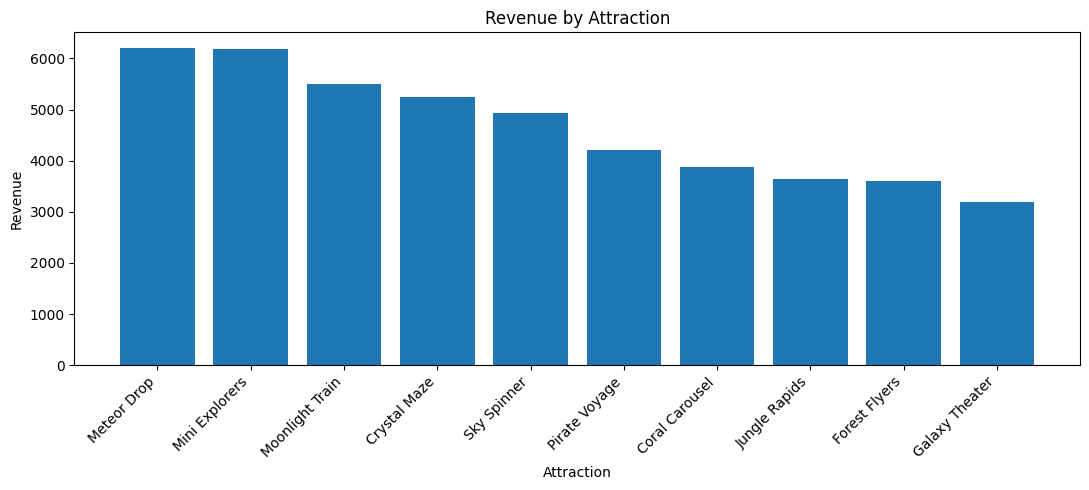

In [0]:
pdf = gold_attraction.toPandas()

pdf = pdf.dropna(subset=["attraction_name"])

pdf["revenue"] = pdf["revenue"].fillna(0)

pdf = pdf.sort_values("revenue", ascending=False)

plt.figure(figsize=(11, 5))

plt.bar(
    pdf["attraction_name"].astype(str),
    pdf["revenue"])

plt.title("Revenue by Attraction")
plt.xlabel("Attraction")
plt.ylabel("Revenue")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

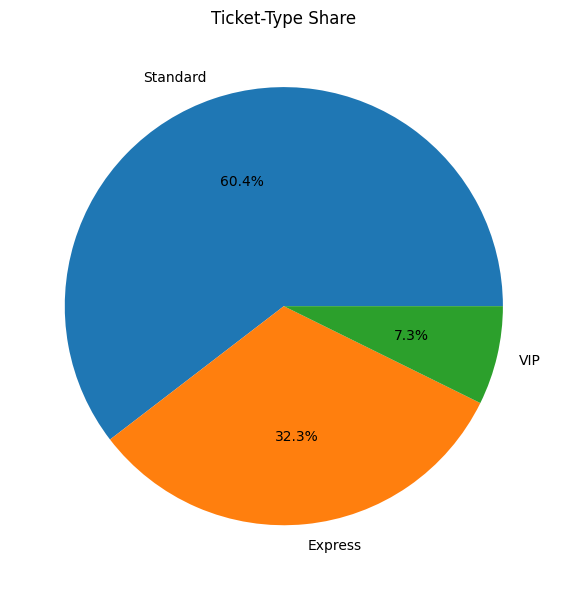

In [0]:
ticket_pdf = (completed.groupBy("ticket_type").count().toPandas())
plt.figure(figsize=(6, 6))
plt.pie(ticket_pdf["count"], labels=ticket_pdf["ticket_type"], autopct="%1.1f%%")
plt.title("Ticket-Type Share")
plt.tight_layout()
plt.show()

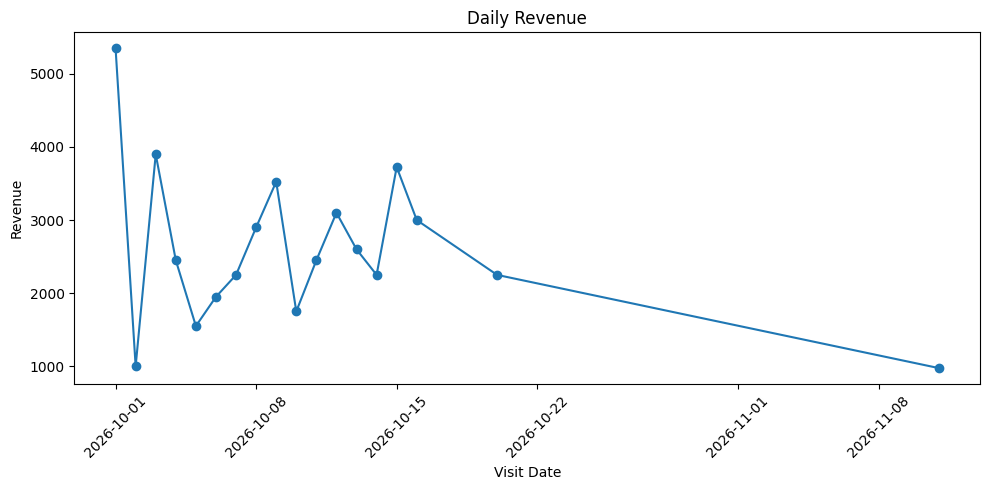

In [0]:
daily_pdf = (completed.withColumn("visit_date", F.to_date("visit_date"))
    .groupBy("visit_date").agg(F.sum("ticket_price").alias("revenue"))
    .orderBy("visit_date").toPandas())
plt.figure(figsize=(10, 5))
plt.plot(daily_pdf["visit_date"], daily_pdf["revenue"], marker="o")
plt.title("Daily Revenue")
plt.xlabel("Visit Date")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

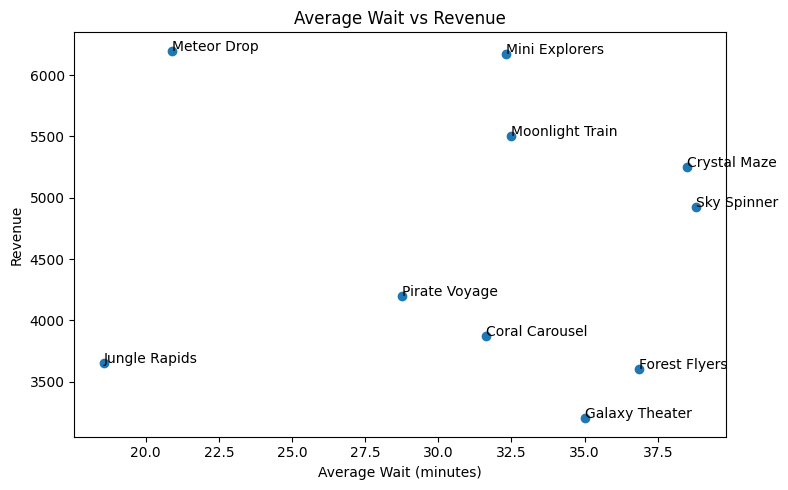

In [0]:
plt.figure(figsize=(8, 5))
plt.scatter(pdf["average_wait_minutes"], pdf["revenue"])
for _, row in pdf.iterrows():
    plt.annotate(str(row["attraction_name"]), (row["average_wait_minutes"], row["revenue"]))
plt.title("Average Wait vs Revenue")
plt.xlabel("Average Wait (minutes)")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

In [0]:
print("Attractions in Gold:", gold_attraction.count())
print("Zones in Gold:", gold_zone.count())
print("Total Gold revenue:", completed.agg(F.sum("ticket_price")).first()[0])

Attractions in Gold: 11
Zones in Gold: 5
Total Gold revenue: 46975.0
